# Feature correlation / redundancy check

Exploratory only — this notebook never touches `src/`. Goal: for one catalog category at a time, find pairs of features that are near-duplicates of each other (|corr| > 0.9) so a future, separate change can drop the redundant one before training.

**Important:** this checks correlation *between features*, never feature-vs-target. Picking features by their correlation with future returns on the full history would leak look-ahead information; checking whether two inputs are redundant with each other does not.

In [6]:
import sys
sys.path.insert(0, "..")  # so `import src...` works from notebooks/

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.config import load_config
from src.market_service import MarketService
from src.ephemeris import AstroSettings

cfg = load_config("../config.yaml")
ms = MarketService(cfg)
s = AstroSettings.from_cfg(cfg)

SYMBOL = "^BSESN"
px = ms.daily(SYMBOL)
cal = ms.calendar(SYMBOL, px.index)
px.tail()

,ts_utc,open,high,low,close,adj_close,volume,price,pct_change,log_ret
date,,,,,,,,,,
2026-10-13,2026-10-13 10:00:00+00:00,71951.726562,73045.671875,71703.562500,73033.781250,73033.781250,24700.0,73033.781250,0.015420,0.015303
2026-10-14,2026-10-14 10:00:00+00:00,73049.757812,73195.257812,72578.750000,72781.890625,72781.890625,12700.0,72781.890625,-0.003449,-0.003455
2026-10-15,2026-10-15 10:00:00+00:00,72965.796875,74330.289062,72896.382812,74315.609375,74315.609375,23300.0,74315.609375,0.021073,0.020854
2026-10-16,2026-10-16 10:00:00+00:00,74341.078125,74778.781250,74012.992188,74729.273438,74729.273438,22000.0,74729.273438,0.005566,0.005551
2026-10-19,2026-10-19 10:00:00+00:00,74849.296875,74849.750000,73708.539062,73852.898438,73852.898438,14800.0,73852.898438,-0.011727,-0.011797


## Category 16-18: Astrology (most near-duplicate features of any category)

In [7]:
from src.astrology import sky_table
from src.exchanges import session_time_utc
from src.catalog_features import astro_positions, astro_aspects, astro_vedic

sky = sky_table(session_time_utc(cal.ex, px.index, "open"), s, index=px.index)
astro_feats = pd.concat([astro_positions(sky), astro_aspects(sky), astro_vedic(sky)], axis=1)
print(astro_feats.shape)
astro_feats.head()

(6606, 180)


,sun_longitude_sin,sun_longitude_cos,sun_longitude_speed_deg_day,moon_longitude_sin,moon_longitude_cos,moon_longitude_speed_deg_day,mercury_longitude_sin,mercury_longitude_cos,mercury_longitude_speed_deg_day,mercury_retrograde_flag,...,sun_rashi_id,moon_rashi_id,moon_nakshatra_id,moon_nakshatra_pada,tithi_id,yoga_id,karana_id,paksha_flag,new_moon_session_flag,full_moon_session_flag
date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,-0.978882,-0.204425,1.019512,-0.632318,-0.774709,11.853687,-0.943344,-0.331817,1.565174,0.0,...,8.0,7.0,16.0,2.0,27.0,9.0,3.0,1.0,0.0,0.0
2000-01-04,-0.982365,-0.186975,1.019556,-0.777735,-0.628592,11.818209,-0.952070,-0.305880,1.570827,0.0,...,8.0,7.0,17.0,2.0,28.0,10.0,5.0,1.0,0.0,0.0
2000-01-05,-0.985536,-0.169465,1.019577,-0.889984,-0.455992,11.822930,-0.960111,-0.279618,1.576683,0.0,...,8.0,8.0,18.0,1.0,29.0,11.0,7.0,1.0,0.0,0.0
2000-01-06,-0.988396,-0.151902,1.019574,-0.964608,-0.263687,11.862158,-0.967455,-0.253044,1.582757,0.0,...,8.0,8.0,19.0,1.0,30.0,12.0,8.0,1.0,1.0,0.0
2000-01-07,-0.990942,-0.134290,1.019547,-0.998246,-0.059204,11.932604,-0.974087,-0.226172,1.589060,0.0,...,8.0,8.0,19.0,4.0,1.0,13.0,10.0,0.0,1.0,0.0


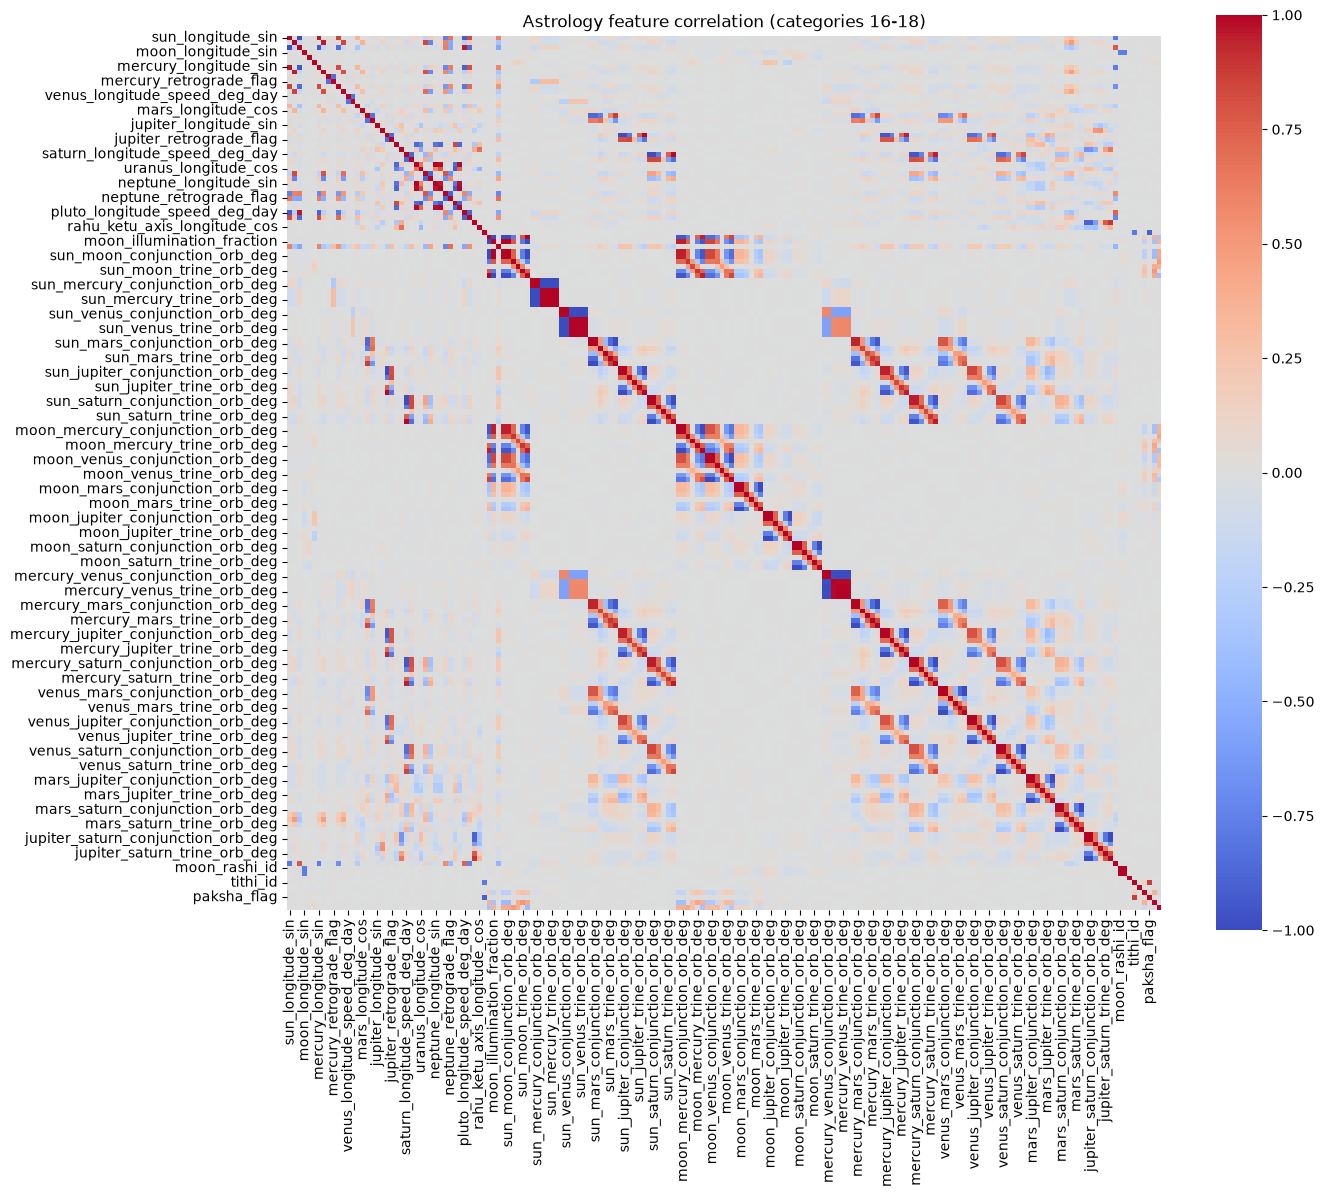

moon_jupiter_conjunction_orb_deg     moon_jupiter_opposition_orb_deg      1.000000
sun_mars_angular_separation_deg      sun_mars_conjunction_orb_deg         1.000000
moon_jupiter_angular_separation_deg  moon_jupiter_conjunction_orb_deg     1.000000
mercury_saturn_conjunction_orb_deg   mercury_saturn_opposition_orb_deg    1.000000
moon_jupiter_angular_separation_deg  moon_jupiter_opposition_orb_deg      1.000000
                                                                            ...   
mercury_mars_opposition_orb_deg      sun_mars_opposition_orb_deg          0.941307
neptune_longitude_cos                pluto_longitude_sin                  0.936381
pluto_longitude_speed_deg_day        sun_longitude_sin                    0.928421
moon_phase_sin                       paksha_flag                          0.903928
pluto_longitude_cos                  pluto_longitude_sin                  0.903018
Length: 177, dtype: float64

In [8]:
def plot_corr(feats: pd.DataFrame, title: str, figsize=(14, 12)):
    corr = feats.corr()
    plt.figure(figsize=figsize)
    sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return corr


def redundant_pairs(corr: pd.DataFrame, threshold: float = 0.9) -> pd.Series:
    """Feature pairs (excluding self-pairs) with |correlation| above `threshold`, most-correlated first."""
    masked = corr.abs().where(~np.eye(len(corr), dtype=bool))
    pairs = masked.stack().sort_values(ascending=False)
    pairs = pairs[pairs.index.map(lambda ix: ix[0] < ix[1])]  # drop mirrored duplicates (a,b) vs (b,a)
    return pairs[pairs > threshold]


astro_corr = plot_corr(astro_feats, "Astrology feature correlation (categories 16-18)")
redundant_pairs(astro_corr)

## Category 02/03/04: Technical / volume / volatility

Swap in whichever category you want to check next — same pattern every time: build the feature frame, plot the heatmap, list redundant pairs.

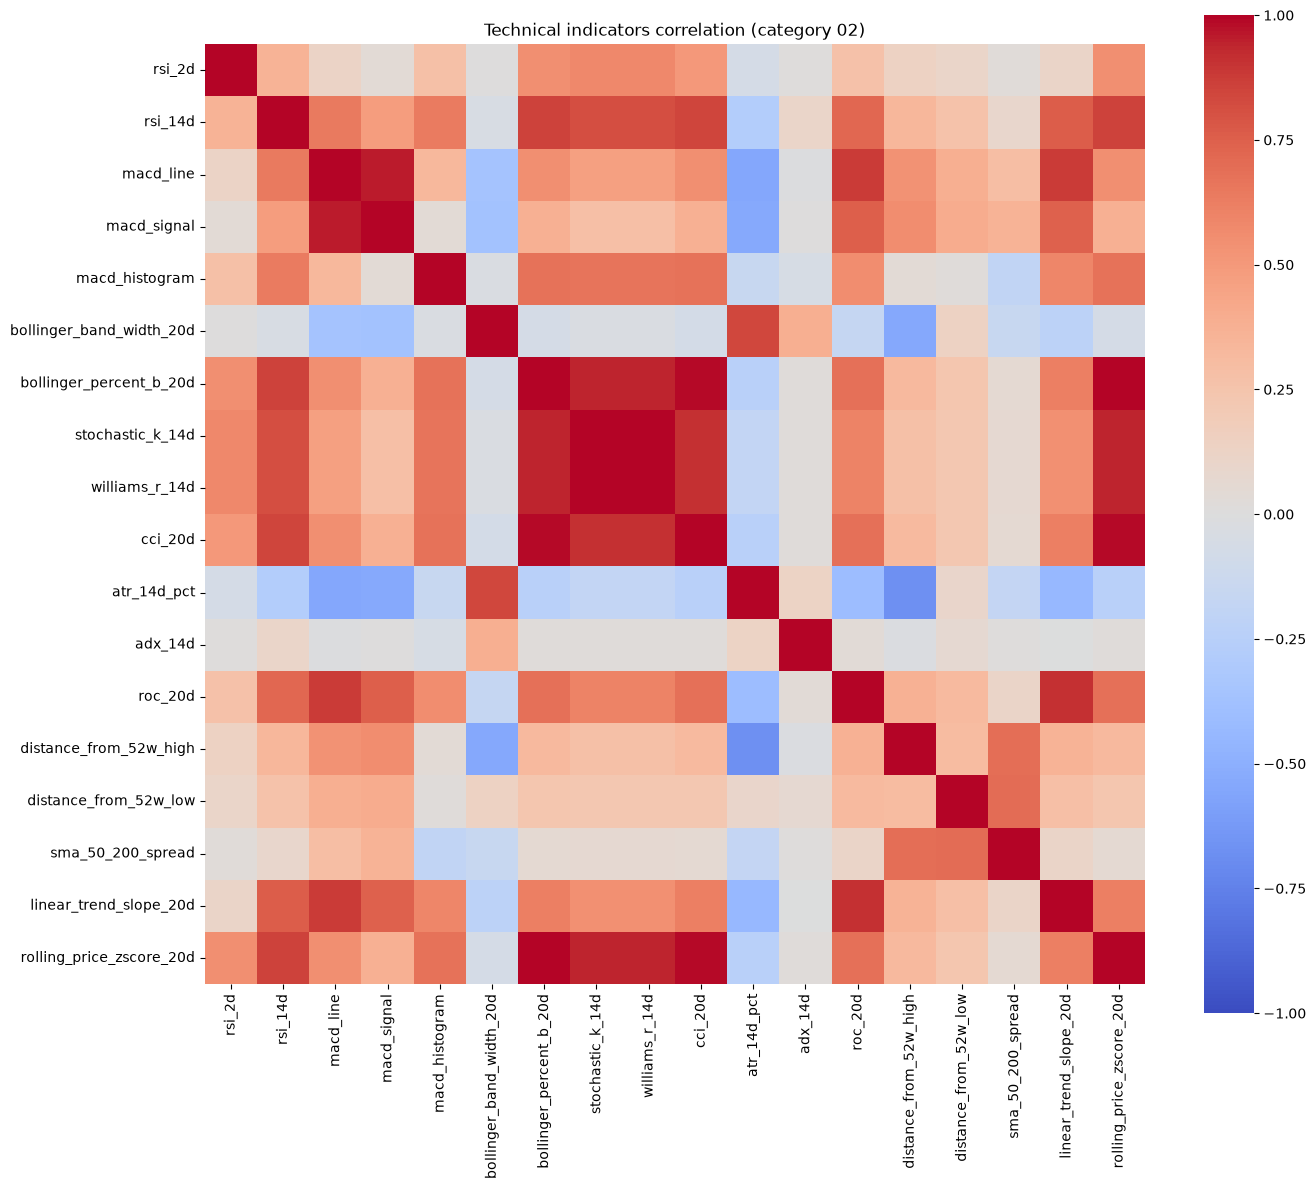

bollinger_percent_b_20d   rolling_price_zscore_20d    1.000000
stochastic_k_14d          williams_r_14d              1.000000
bollinger_percent_b_20d   cci_20d                     0.987453
cci_20d                   rolling_price_zscore_20d    0.987453
macd_line                 macd_signal                 0.956456
bollinger_percent_b_20d   williams_r_14d              0.940718
                          stochastic_k_14d            0.940718
rolling_price_zscore_20d  williams_r_14d              0.940718
                          stochastic_k_14d            0.940718
linear_trend_slope_20d    roc_20d                     0.912893
cci_20d                   williams_r_14d              0.911094
                          stochastic_k_14d            0.911094
dtype: float64

In [9]:
from src.catalog_features import technical, volume_liquidity, volatility_risk

tech_feats = technical(px)
tech_corr = plot_corr(tech_feats, "Technical indicators correlation (category 02)")
redundant_pairs(tech_corr)

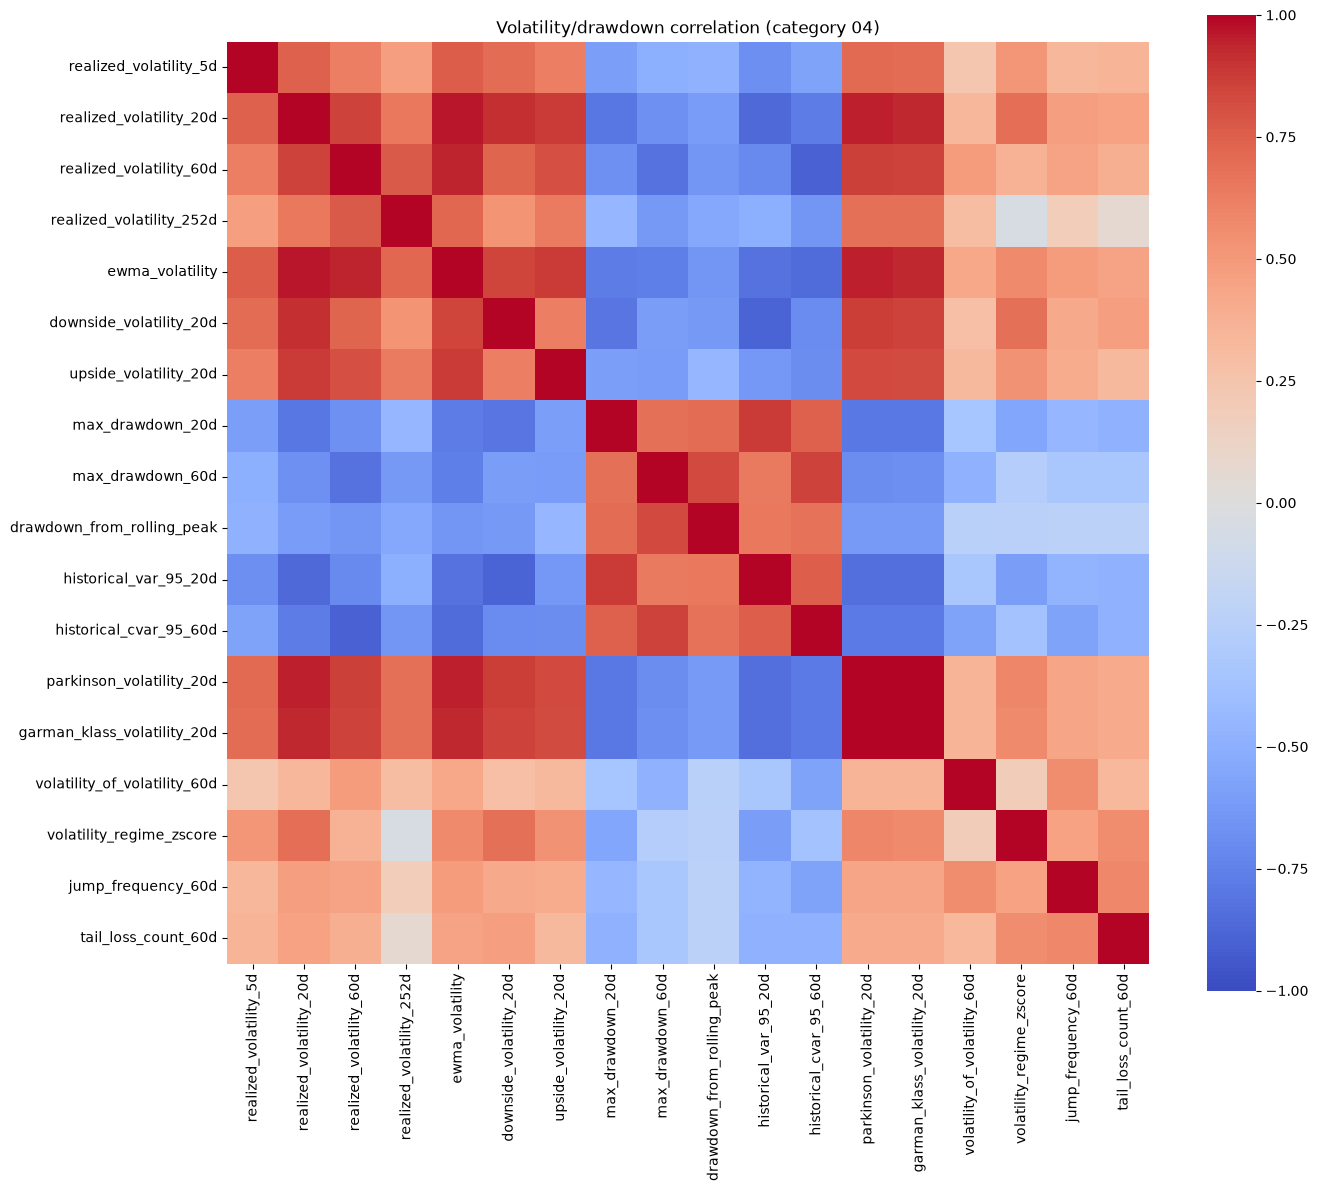

garman_klass_volatility_20d  parkinson_volatility_20d       0.995847
ewma_volatility              realized_volatility_20d        0.963948
parkinson_volatility_20d     realized_volatility_20d        0.950102
ewma_volatility              parkinson_volatility_20d       0.947093
                             realized_volatility_60d        0.940175
                             garman_klass_volatility_20d    0.937277
garman_klass_volatility_20d  realized_volatility_20d        0.935233
downside_volatility_20d      realized_volatility_20d        0.909343
historical_cvar_95_60d       realized_volatility_60d        0.901900
dtype: float64

In [10]:
vol_feats = volatility_risk(px)
vol_corr = plot_corr(vol_feats, "Volatility/drawdown correlation (category 04)")
redundant_pairs(vol_corr)

## Shortlist notes

Keep a running list here of which feature to drop from each redundant pair (prefer the more interpretable or coarser-grained one). This is the input to a later, separate change — this notebook doesn't modify `src/` itself.

- Category 16-18 (astrology): _TBD_
- Category 02 (technical): _TBD_
- Category 04 (volatility): _TBD_